In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

In [2]:
## Load input data
df_labels_final = pd.read_parquet("../data/df_labels_final_12082026_info.parquet")

df_labels_final = df_labels_final.dropna(subset=["Label", "pred_label"])

In [3]:
from joblib import load

model_f = load("../data/models/argus_calibrated_xgb_model_f.pkl")
model_m = load("../data/models/argus_calibrated_xgb_model_m.pkl")

input_cols = list(model_f.feature_names_in_)
input_cols = [str(c) for c in input_cols]

In [4]:
eng_col_labels = {
    "Age": "Age",
    "BMI": "BMI",
    "DiastolicBP": "Diastolic BP",
    "SystolicBP": "Systolic BP",
    "ALAT": "ALAT",
    "ASAT": "ASAT",
    "CRP": "CRP",
    "Cholesterol": "Cholesterol",
    "GGT": "GGT",
    "Glucose": "Glucose",
    "HDL Cholesterol": "HDL cholesterol",
    "Hemoglobine": "Hemoglobin",
    "Kalium": "Potassium",
    "Kreatinine": "Creatinine",
    "LD": "LDH",
    "LDL Cholesterol": "LDL cholesterol",
    "Leucocyten": "Leukocytes",
    "MCH": "MCH",
    "MCHC": "MCHC",
    "MCV": "MCV",
    "Natrium": "Sodium",
    "TSH": "TSH",
    "Triglyceriden": "Triglycerides",
    "Trombocyten": "Platelets",
    "eGFR (CKD-EPI)": "eGFR (CKD-EPI)",
    "InjClsInfarction": "Infarction (injury class)",
    "ST_deviation_index_Anterior": "ST deviation index (anterior)",
    "ST_deviation_index_Inferior": "ST deviation index (inferior)",
    "ST_deviation_index_Lateral": "ST deviation index (lateral)",
    "T_morphology_score_Anterior": "T morphology score (anterior)",
    "T_morphology_score_Inferior": "T morphology score (inferior)",
    "T_morphology_score_Lateral": "T morphology score (lateral)",
    "Regional_ischemia_Anterior": "Regional ischemia (anterior)",
    "Regional_ischemia_Inferior": "Regional ischemia (inferior)",
    "Regional_ischemia_Lateral": "Regional ischemia (lateral)",
}

eng_col_labels_with_units = {
    "Age": "Age (years)",
    "BMI": "BMI (kg/m^2)",
    "DiastolicBP": "Diastolic BP (mmHg)",
    "SystolicBP": "Systolic BP (mmHg)",
    "ALAT": "ALAT (U/L)",
    "ASAT": "ASAT (U/L)",
    "CRP": "CRP (mg/L)",
    "Cholesterol": "Cholesterol (mmol/L)",
    "GGT": "GGT (U/L)",
    "Glucose": "Glucose (mmol/L)",
    "HDL Cholesterol": "HDL cholesterol (mmol/L)",
    "Hemoglobine": "Hemoglobin (mmol/L)",
    "Kalium": "Potassium (mmol/L)",
    "Kreatinine": "Creatinine (µmol/L)",
    "LD": "LDH (U/L)",
    "LDL Cholesterol": "LDL cholesterol (mmol/L)",
    "Leucocyten": "Leukocytes (x10^9/L)",
    "MCH": "MCH (fmol)",
    "MCHC": "MCHC (mmol/L)",
    "MCV": "MCV (fL)",
    "Natrium": "Sodium (mmol/L)",
    "TSH": "TSH (mIU/L)",
    "Triglyceriden": "Triglycerides (mmol/L)",
    "Trombocyten": "Platelets (x10^9/L)",
    "eGFR (CKD-EPI)": "eGFR (CKD-EPI)",
    "InjClsInfarction": "Infarction (binary injury class)",
    "ST_deviation_index_Anterior": "ST deviation index anterior (arb. units)",
    "ST_deviation_index_Inferior": "ST deviation index inferior (arb. units)",
    "ST_deviation_index_Lateral": "ST deviation index lateral (arb. units)",
    "T_morphology_score_Anterior": "T morphology score anterior (arb. units)",
    "T_morphology_score_Inferior": "T morphology score inferior (arb. units)",
    "T_morphology_score_Lateral": "T morphology score lateral (arb. units)",
    "Regional_ischemia_Anterior": "Regional ischemia anterior (arb. units)",
    "Regional_ischemia_Inferior": "Regional ischemia inferior (arb. units)",
    "Regional_ischemia_Lateral": "Regional ischemia lateral (arb. units)",
}

In [5]:
n_unique_patients = df_labels_final["patientPseuID"].nunique()
print(f"Number of unique patients with CAD related symptoms, physical first consultation: {n_unique_patients}")
print(df_labels_final.shape)

# Age distribution by gender (one row per patient)
print(df_labels_final.drop_duplicates(subset=["patientPseuID", "Index_dt"]).groupby("gender")["Age"].describe())

print(
    f"Percentage female: {100 / df_labels_final.shape[0] * len(df_labels_final.loc[df_labels_final['gender'] == '1'])}"
)

Number of unique patients with CAD related symptoms, physical first consultation: 882
(889, 69)
        count       mean        std   min   25%   50%   75%   max
gender                                                           
0       445.0  60.991011  16.737639  18.0  53.0  63.0  74.0  92.0
1       444.0  59.238739  16.969678  18.0  50.0  62.0  73.0  92.0
Percentage female: 49.9437570303712


# Table 1 info for model performance cohort

In [6]:
import pandas as pd


def missingness_marker(pct_missing):
    """Return asterisk marker based on % missing."""
    if pct_missing > 80:
        return "+++"
    elif pct_missing > 70:
        return "++"
    elif pct_missing > 60:
        return "+"
    else:
        return ""


def gender_mean_sd_table(
    df, columns=None, group_col="gender", csv_path=None, decimals=1, group_labels=None, group_totals=None
):
    """
    Compute 'mean (SD sd)*' per gender for given columns,
    with asterisk markers indicating missingness severity.

    Parameters
    ----------
    df : pd.DataFrame
    columns : list of str, optional
        Columns to summarize. If None, uses all numeric columns (excluding group_col).
    group_col : str
        Column to group by (default "gender").
    csv_path : str, optional
        If given, writes the resulting table to this path as CSV.
    decimals : int
        Number of decimals to round to.
    group_labels : dict, optional
        Mapping from raw group values to display labels, e.g. {"0": "Male", "1": "Female"}.
    group_totals : dict
        Mapping from raw group values to total N for that group, e.g. {"0": 485, "1": 486}.
        Required for correct missingness percentages.

    Returns
    -------
    pd.DataFrame with one row per variable, one column per group.
    """
    if columns is None:
        columns = df.select_dtypes(include="number").columns.tolist()
        columns = [c for c in columns if c != group_col]

    stats = df.groupby(group_col)[columns].agg(["mean", "std", "count"])

    groups = stats.index.tolist()
    labels = [group_labels.get(g, g) if group_labels else g for g in groups]

    rows = []
    for col in columns:
        row = {"variable": col}
        for grp, label in zip(groups, labels, strict=False):
            mean = stats.loc[grp, (col, "mean")]
            sd = stats.loc[grp, (col, "std")]
            n = stats.loc[grp, (col, "count")]
            total = group_totals.get(grp) if group_totals else df[df[group_col] == grp].shape[0]
            pct_available = 100 * n / total if total else float("nan")
            pct_missing = 100 - pct_available
            marker = missingness_marker(pct_missing)
            row[label] = f"{mean:.{decimals}f} (SD {sd:.{decimals}f}){marker}"
        rows.append(row)

    table = pd.DataFrame(rows).set_index("variable")

    print(table.to_string())
    print("\n+ = Data missing for 60-70% of the records")
    print("++ = Data missing for 70-80% of the records")
    print("+++ = Data missing for > 80% of the records")
    print("(unmarked = Data missing for < 5% of the records)")

    if csv_path:
        table.to_csv(csv_path)
        with open(csv_path, "a") as f:
            f.write("\n")
            f.write("+ = Data missing for 60-70% of the records\n")
            f.write("++ = Data missing for 70-80% of the records\n")
            f.write("+++ = Data missing for > 80% of the records\n")
            f.write("(unmarked) = Data missing for < 5% of the records\n")
        print(f"\nSaved to {csv_path}")

    return table


table = gender_mean_sd_table(
    df_labels_final.rename(columns=eng_col_labels_with_units),
    group_labels={"0": "Male", "1": "Female"},
    group_totals={"0": 445, "1": 444},
    csv_path="output/gender_summary_with_markers.csv",
)

                                                          Male               Female
variable                                                                           
Age (years)                                     61.0 (SD 16.7)       59.2 (SD 17.0)
BMI (kg/m^2)                                    27.0 (SD 4.7)+      26.8 (SD 5.1)++
Diastolic BP (mmHg)                          79.3 (SD 14.4)+++     76.3 (SD 8.7)+++
Systolic BP (mmHg)                          139.2 (SD 21.1)+++   130.9 (SD 19.5)+++
ALAT (U/L)                                    31.9 (SD 18.4)++    25.0 (SD 17.7)+++
ASAT (U/L)                                    26.4 (SD 13.8)++    25.5 (SD 21.1)+++
CRP (mg/L)                                     3.8 (SD 5.9)+++     8.2 (SD 17.5)+++
Cholesterol (mmol/L)                           4.5 (SD 1.4)+++      5.1 (SD 1.2)+++
GGT (U/L)                                    61.1 (SD 101.0)++    40.9 (SD 70.2)+++
Glucose (mmol/L)                                6.6 (SD 2.3)++      6.0 (SD 

# Label info

In [7]:
cols_check = [
    "Order_Ok",
    "Verrichting_Ok",
    "Ver_Rad_MRI_PET_SPECT",
    "Ver_Rad_CT",
    "CT_rapport",
    "MRI_order",
    "CT_order",
    "CT_Bram",
]

conditions = [
    (df_labels_final[["Order_Ok", "Verrichting_Ok", "Ver_Rad_MRI_PET_SPECT", "MRI_order"]] == 1).any(axis=1),
    df_labels_final[cols_check].isna().all(axis=1),  # no info at all -> Label = 0
    df_labels_final["CT_based_CAD"] == 1,  # CT report positive
    df_labels_final["cacs_zero"] == 1,  # CACS = 0
]
choices = [
    "Clinical order/referral",
    "No information available (Label=0)",
    "CT report: CAD finding",
    "CT report: CACS=0",
]
df_labels_final["Label_source"] = np.select(conditions, choices, default="Unlabeled")

# Sanity check: every row should have a source, no "Unlabeled" left
print(df_labels_final["Label_source"].value_counts(dropna=False))

Label_source
No information available (Label=0)    569
Clinical order/referral               264
CT report: CAD finding                 47
CT report: CACS=0                       9
Name: count, dtype: int64


In [8]:
label_source_table = (
    df_labels_final.groupby("Label_source")
    .agg(
        N=("Label_source", "size"),
        N_patients=("patientPseuID", "nunique"),
        Label_1=("Label", lambda x: (x == 1).sum()),
        Label_0=("Label", lambda x: (x == 0).sum()),
    )
    .assign(Pct_of_cohort=lambda d: (d["N"] / d["N"].sum() * 100).round(1))
    .reset_index()
    .sort_values("N", ascending=False)
)

label_source_table

,Label_source,N,N_patients,Label_1,Label_0,Pct_of_cohort
3,No information available (Label=0),569,565,0,569,64.0
2,Clinical order/referral,264,262,264,0,29.7
1,CT report: CAD finding,47,46,47,0,5.3
0,CT report: CACS=0,9,9,0,9,1.0


# Performance assesment

For the performance assesment we drop the inconclusive labels

In [9]:
print(df_labels_final["Label"].value_counts())
print(df_labels_final["pred_label"].value_counts())

Label
0.0    578
1.0    311
Name: count, dtype: int64
pred_label
0    601
1    288
Name: count, dtype: int64


In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(df_labels_final["Label"], df_labels_final["pred_label"])
print(cm)

[[413 165]
 [188 123]]


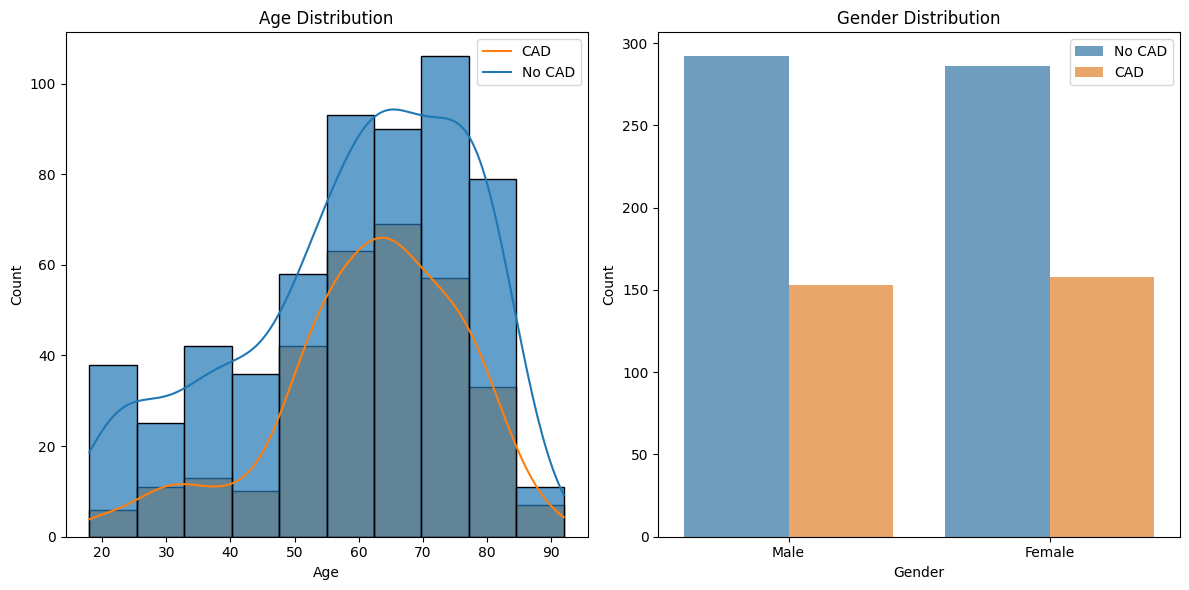

Number of patients: 882
number of entries: 889


In [11]:
# plot gender and age distribution with label as hue
plt.figure(figsize=(12, 6))

label_order = [0, 1]  # 0 = No CAD, 1 = CAD

# Age distribution with label hue
plt.subplot(1, 2, 1)
sns.histplot(data=df_labels_final, x="Age", hue="Label", bins=10, alpha=0.7, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend(
    [
        "CAD",
        "No CAD",
    ]
)

# Gender distribution with label hue
plt.subplot(1, 2, 2)
sns.countplot(data=df_labels_final, x="gender", hue="Label", alpha=0.7, hue_order=label_order)
plt.xticks([0, 1], ["Male", "Female"])
plt.xticks([0, 1], ["Male", "Female"])
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, ["No CAD", "CAD"], loc="upper right", frameon=True)


plt.tight_layout()
plt.show()

# print value_counts for gender and label combination
pd.crosstab(df_labels_final["gender"], df_labels_final["Label"], margins=True)

print(f"Number of patients: {df_labels_final['patientPseuID'].nunique()}")
print(f"number of entries: {len(df_labels_final)}")


# Split per gender

In [12]:
df_female = df_labels_final.loc[df_labels_final["gender"] == "1"]
df_male = df_labels_final.loc[df_labels_final["gender"] == "0"]

## Visualize distribution of the prediction outcome

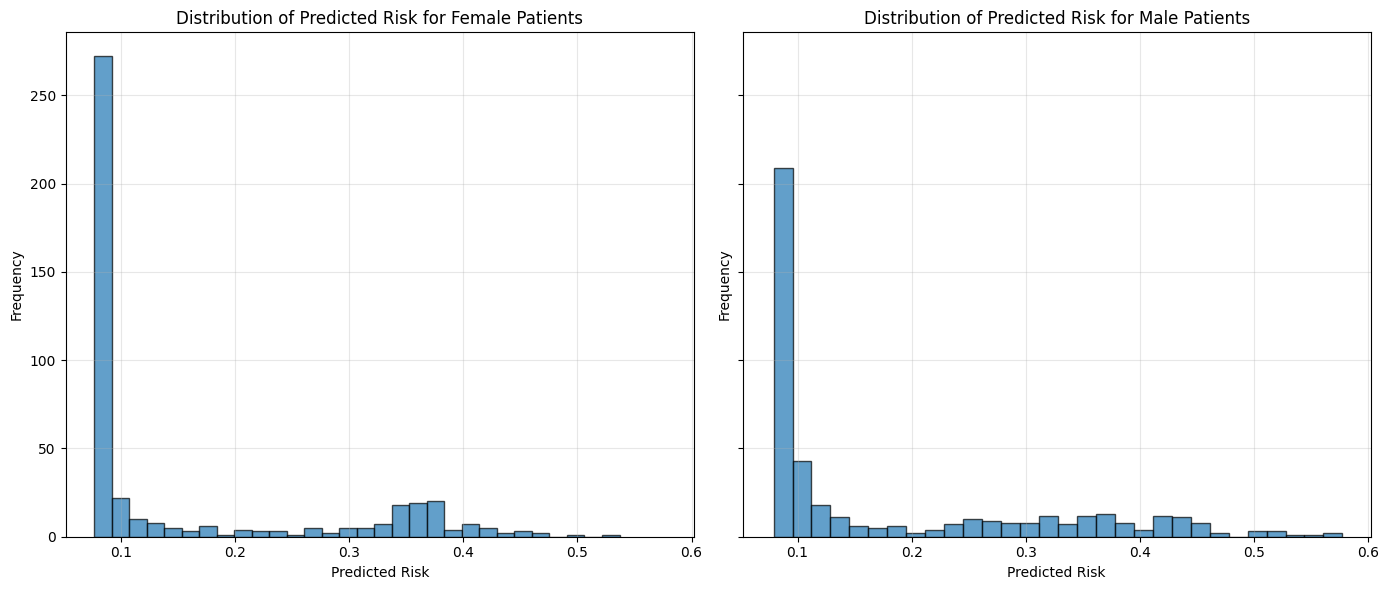

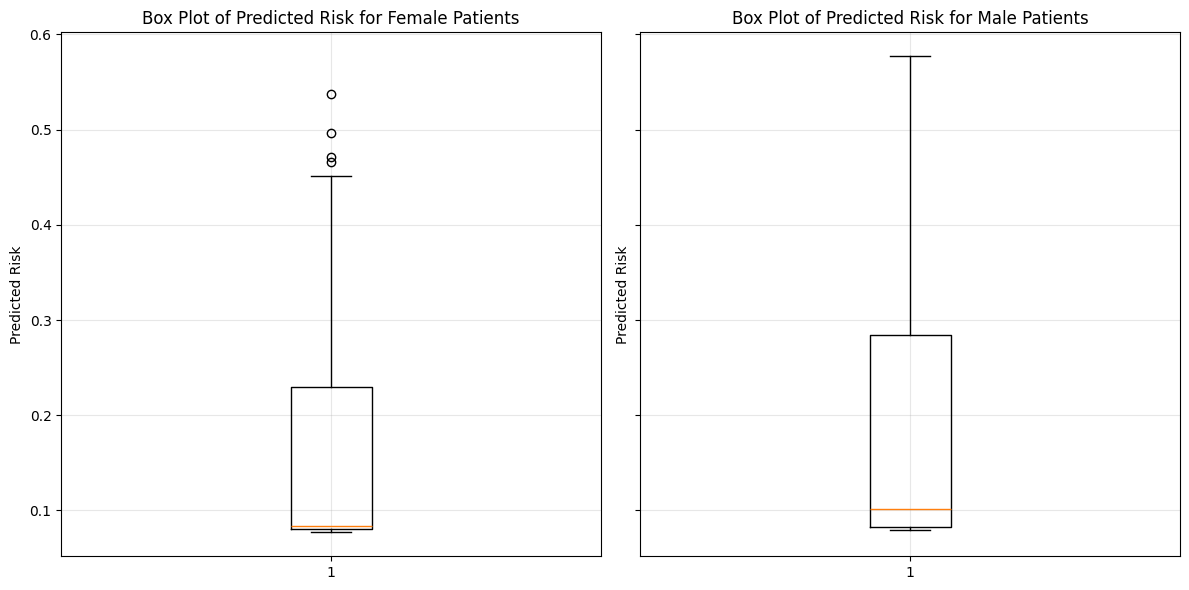

Summary statistics for predicted_risk (Female):
count    444.000000
mean       0.157753
std        0.121226
min        0.076842
25%        0.080586
50%        0.083594
75%        0.229212
max        0.536889
Name: predicted_risk, dtype: float64

Summary statistics for predicted_risk (Male):
count    445.000000
mean       0.182059
std        0.132656
min        0.079000
25%        0.082625
50%        0.101532
75%        0.283994
max        0.577172
Name: predicted_risk, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

axes[0].hist(df_female["predicted_risk"], bins=30, alpha=0.7, edgecolor="black")
axes[0].set_xlabel("Predicted Risk")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Predicted Risk for Female Patients")
axes[0].grid(True, alpha=0.3)

axes[1].hist(df_male["predicted_risk"], bins=30, alpha=0.7, edgecolor="black")
axes[1].set_xlabel("Predicted Risk")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Predicted Risk for Male Patients")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Box plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

axes[0].boxplot(df_female["predicted_risk"], vert=True)
axes[0].set_ylabel("Predicted Risk")
axes[0].set_title("Box Plot of Predicted Risk for Female Patients")
axes[0].grid(True, alpha=0.3)

axes[1].boxplot(df_male["predicted_risk"], vert=True)
axes[1].set_ylabel("Predicted Risk")
axes[1].set_title("Box Plot of Predicted Risk for Male Patients")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print("Summary statistics for predicted_risk (Female):")
print(df_female["predicted_risk"].describe())
print("\nSummary statistics for predicted_risk (Male):")
print(df_male["predicted_risk"].describe())

# Calibration

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import brier_score_loss
from statsmodels.nonparametric.smoothers_lowess import lowess


def plot_calibration_curve_smoothed(groups, method="loess", frac=0.6667, show_ci=True, n_bootstraps=200, alpha=0.05):
    """
    Plot smoothed calibration curves (LOESS) for multiple groups on one figure.
    Prints calibration intercept, slope, and Brier score per group.

    Parameters
    ----------
    groups : dict
        group_name -> (y_true, y_proba, color)
    method : {'loess'}
        Smoothing method. Currently LOESS; RCS can be added if needed.
    frac : float
        LOESS smoothing span (fraction of data used per local fit).
        Lower = wigglier/more local, higher = smoother. 0.3-0.7 is typical.
    show_ci : bool
        If True, adds a bootstrap confidence band around each smoothed curve.
    n_bootstraps : int
        Number of bootstrap resamples for the confidence band.
    """
    plt.figure(figsize=(8, 6))
    results = {}

    for name, (y_true, y_proba, color) in groups.items():
        y_true = np.asarray(y_true)
        y_proba = np.asarray(y_proba)

        order = np.argsort(y_proba)
        x_sorted, y_sorted = y_proba[order], y_true[order]

        smoothed = lowess(y_sorted, x_sorted, frac=frac, return_sorted=True)
        x_smooth, y_smooth = smoothed[:, 0], smoothed[:, 1]

        eps = 1e-6
        p_clip = np.clip(y_proba, eps, 1 - eps)
        logit_p = np.log(p_clip / (1 - p_clip))
        X = sm.add_constant(logit_p)
        model = sm.Logit(y_true, X).fit(disp=0)
        intercept, slope = model.params[0], model.params[1]
        intercept_ci = tuple(model.conf_int(alpha=alpha)[0])
        slope_ci = tuple(model.conf_int(alpha=alpha)[1])

        brier = brier_score_loss(y_true, y_proba)

        print(f"=== Calibration Metrics: {name} (LOESS frac={frac}) ===")
        print(
            f"Calibration Intercept (ideal=0): {intercept:.3f} "
            f"(95% CI: {intercept_ci[0]:.3f}\u2013{intercept_ci[1]:.3f})"
        )
        print(f"Calibration Slope (ideal=1):     {slope:.3f} (95% CI: {slope_ci[0]:.3f}\u2013{slope_ci[1]:.3f})")
        print(f"Brier Score (lower=better):      {brier:.4f}\n")

        if show_ci:
            rng = np.random.RandomState(42)
            n = len(y_true)
            eval_x = np.linspace(x_sorted.min(), x_sorted.max(), 200)
            boot_curves = []
            for _ in range(n_bootstraps):
                idx = rng.randint(0, n, n)
                xb, yb = y_proba[idx], y_true[idx]
                order_b = np.argsort(xb)
                sm_b = lowess(yb[order_b], xb[order_b], frac=frac, return_sorted=True)
                interp = np.interp(eval_x, sm_b[:, 0], sm_b[:, 1])
                boot_curves.append(interp)
            boot_curves = np.array(boot_curves)
            lower = np.percentile(boot_curves, 100 * alpha / 2, axis=0)
            upper = np.percentile(boot_curves, 100 * (1 - alpha / 2), axis=0)
            plt.fill_between(eval_x, lower, upper, color=color, alpha=0.15)

        plt.plot(x_smooth, y_smooth, "-", label=name, color=color, linewidth=2)

        results[name] = {
            "calibration_intercept": intercept,
            "calibration_intercept_ci": intercept_ci,
            "calibration_slope": slope,
            "calibration_slope_ci": slope_ci,
            "brier_score": brier,
        }

    plt.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
    plt.xlabel("Predicted Probability")
    plt.ylabel("Observed Probability (LOESS smoothed)")
    plt.title("Calibration Curve (smoothed)")
    plt.legend()
    plt.grid()
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.show()

    return results

=== Calibration Metrics: Male (LOESS frac=0.6667) ===
Calibration Intercept (ideal=0): -0.382 (95% CI: -0.822–0.059)
Calibration Slope (ideal=1):     0.156 (95% CI: -0.079–0.390)
Brier Score (lower=better):      0.2627

=== Calibration Metrics: Female (LOESS frac=0.6667) ===
Calibration Intercept (ideal=0): 0.308 (95% CI: -0.177–0.794)
Calibration Slope (ideal=1):     0.485 (95% CI: 0.243–0.727)
Brier Score (lower=better):      0.2616



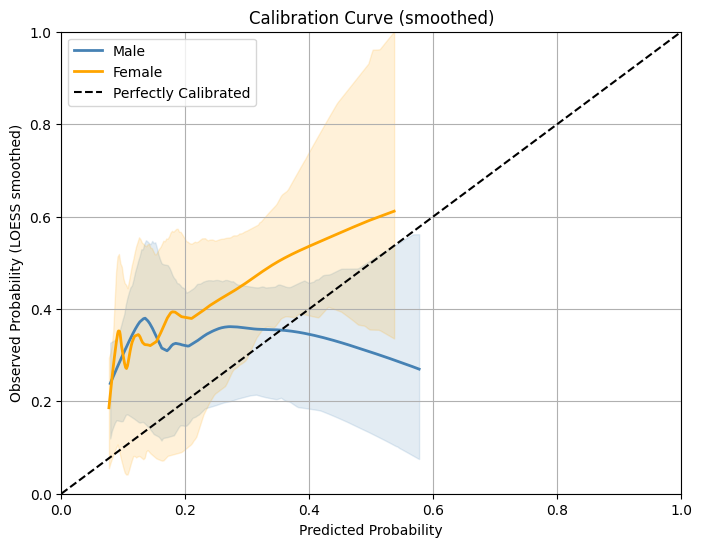

In [15]:
results = plot_calibration_curve_smoothed(
    {
        "Male": (df_male["Label"], df_male["predicted_risk"], "steelblue"),
        "Female": (df_female["Label"], df_female["predicted_risk"], "orange"),
    },
    frac=0.6667,  # statsmodels default LOESS span
    show_ci=True,
    n_bootstraps=200,
)

# Discrimination 


In [16]:
from sklearn.metrics import roc_auc_score

print("Male AUC:", round(roc_auc_score(df_male["Label"], df_male["predicted_risk"]), 3))
print("Female AUC:", round(roc_auc_score(df_female["Label"], df_female["predicted_risk"]), 3))

Male AUC: 0.555
Female AUC: 0.618


In [17]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    make_scorer,
    roc_auc_score,
    roc_curve,
)


def inverted_f1_score(y_true, y_pred):
    """
    Calculate the inverted F1 score.
    """
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0

    return 2 * (npv * specificity) / (npv + specificity) if (npv + specificity) > 0 else 0


def negative_predictive_value(y_true, y_pred):
    """
    Calculate the negative predictive value.
    """
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    return tn / (tn + fn) if (tn + fn) > 0 else 0


def specificity(y_true, y_pred):
    """
    Calculate the specificity.
    """
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))

    return tn / (tn + fp) if (tn + fp) > 0 else 0


inverted_f1_scorer = make_scorer(inverted_f1_score)
npv_scorer = make_scorer(negative_predictive_value)
specificity_scorer = make_scorer(specificity)

In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from statsmodels.stats.proportion import proportion_confint


def bootstrap_auc_ci(y_true, y_score, metric_func, n_bootstraps=1000, alpha=0.05, random_state=42):
    """Percentile bootstrap CI for a ranking metric (AUROC, AUPRC, etc.)."""
    rng = np.random.RandomState(random_state)
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    n = len(y_true)

    scores = []
    for _ in range(n_bootstraps):
        idx = rng.randint(0, n, n)
        y_true_bs = y_true[idx]
        y_score_bs = y_score[idx]
        if len(np.unique(y_true_bs)) < 2:  # skip resamples with only one class
            continue
        scores.append(metric_func(y_true_bs, y_score_bs))

    scores = np.array(scores)
    lower = np.percentile(scores, 100 * alpha / 2)
    upper = np.percentile(scores, 100 * (1 - alpha / 2))
    return lower, upper


def evaluate_model_comprehensive_pred(y_pred, y_test, y_proba=None, alpha=0.05, n_bootstraps=1000):
    """
    Compute classification metrics with CIs.
    Returns a dict: {metric_name: (value, ci_lower, ci_upper_or_None)}
    """
    y_pred = np.asarray(y_pred)
    y_test = np.asarray(y_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    n_total = tn + fp + fn + tp

    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    balanced_acc = (sensitivity + specificity) / 2
    inverted_f1 = inverted_f1_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)

    score_for_ranking = y_proba if y_proba is not None else y_pred
    roc_auc = roc_auc_score(y_test, score_for_ranking)
    auprc = average_precision_score(y_test, score_for_ranking)

    def wilson_ci(count, nobs):
        if nobs == 0:
            return (0, 0)
        return proportion_confint(count=count, nobs=nobs, alpha=alpha, method="wilson")

    npv_ci = wilson_ci(tn, tn + fn)
    ppv_ci = wilson_ci(tp, tp + fp)
    sens_ci = wilson_ci(tp, tp + fn)
    spec_ci = wilson_ci(tn, tn + fp)
    bal_acc_ci = ((sens_ci[0] + spec_ci[0]) / 2, (sens_ci[1] + spec_ci[1]) / 2)
    acc_ci = wilson_ci(tn + tp, n_total)

    roc_auc_ci = bootstrap_auc_ci(y_test, score_for_ranking, roc_auc_score, n_bootstraps=n_bootstraps, alpha=alpha)
    auprc_ci = bootstrap_auc_ci(
        y_test, score_for_ranking, average_precision_score, n_bootstraps=n_bootstraps, alpha=alpha
    )

    results = {
        "ROC AUC": (roc_auc, *roc_auc_ci),
        "AUPRC": (auprc, *auprc_ci),
        "Sensitivity (Recall)": (sensitivity, *sens_ci),
        "Specificity": (specificity, *spec_ci),
        "PPV (Precision)": (ppv, *ppv_ci),
        "NPV": (npv, *npv_ci),
        "Balanced Accuracy": (balanced_acc, *bal_acc_ci),
        "Accuracy": (acc, *acc_ci),
        "Inverted F1": (inverted_f1, np.nan, np.nan),  # no CI computed for this metric
        "TN": (tn, np.nan, np.nan),
        "FP": (fp, np.nan, np.nan),
        "FN": (fn, np.nan, np.nan),
        "TP": (tp, np.nan, np.nan),
    }

    return results

In [19]:
# --- Baseline: classify everyone as 0 ---
baseline_pred_male = np.zeros(len(df_male["Label"]))
baseline_pred_female = np.zeros(len(df_female["Label"]))

# Run all four evaluations (verbose=False to suppress the per-group printout)
runs = {
    "Male": (df_male["pred_label"], df_male["Label"], df_male["predicted_risk"]),
    "Female": (df_female["pred_label"], df_female["Label"], df_female["predicted_risk"]),
    "Male_baseline": (baseline_pred_male, df_male["Label"], None),
    "Female_baseline": (baseline_pred_female, df_female["Label"], None),
}

all_results = {
    name: evaluate_model_comprehensive_pred(y_pred, y_test, y_proba) for name, (y_pred, y_test, y_proba) in runs.items()
}


def format_value_ci(value, ci_lo, ci_hi):
    if np.isnan(ci_lo) or np.isnan(ci_hi):
        return f"{value:.2f}"
    return f"{value:.2f} ({ci_lo:.2f}\u2013{ci_hi:.2f})"


records = {
    group: {metric_name: format_value_ci(value, ci_lo, ci_hi) for metric_name, (value, ci_lo, ci_hi) in metrics.items()}
    for group, metrics in all_results.items()
}

df_metrics_wide = pd.DataFrame(records)
df_metrics_wide.index.name = "Metric"

df_metrics_wide.to_csv("output/model_evaluation_metrics_wide.csv")
df_metrics_wide

,Male,Female,Male_baseline,Female_baseline
Metric,,,,
ROC AUC,0.55 (0.50–0.61),0.62 (0.57–0.67),0.50 (0.50–0.50),0.50 (0.50–0.50)
AUPRC,0.37 (0.32–0.44),0.46 (0.40–0.55),0.34 (0.30–0.39),0.36 (0.31–0.40)
Sensitivity (Recall),0.40 (0.32–0.48),0.39 (0.32–0.47),0.00 (0.00–0.02),0.00 (0.00–0.02)
Specificity,0.66 (0.60–0.71),0.77 (0.72–0.81),1.00 (0.99–1.00),1.00 (0.99–1.00)
PPV (Precision),0.38 (0.31–0.46),0.48 (0.40–0.57),0.00 (0.00–0.00),0.00 (0.00–0.00)
NPV,0.68 (0.62–0.73),0.70 (0.64–0.74),0.66 (0.61–0.70),0.64 (0.60–0.69)
Balanced Accuracy,0.53 (0.46–0.60),0.58 (0.52–0.64),0.50 (0.49–0.51),0.50 (0.49–0.51)
Accuracy,0.57 (0.52–0.62),0.64 (0.59–0.68),0.66 (0.61–0.70),0.64 (0.60–0.69)
Inverted F1,0.67,0.73,0.79,0.78


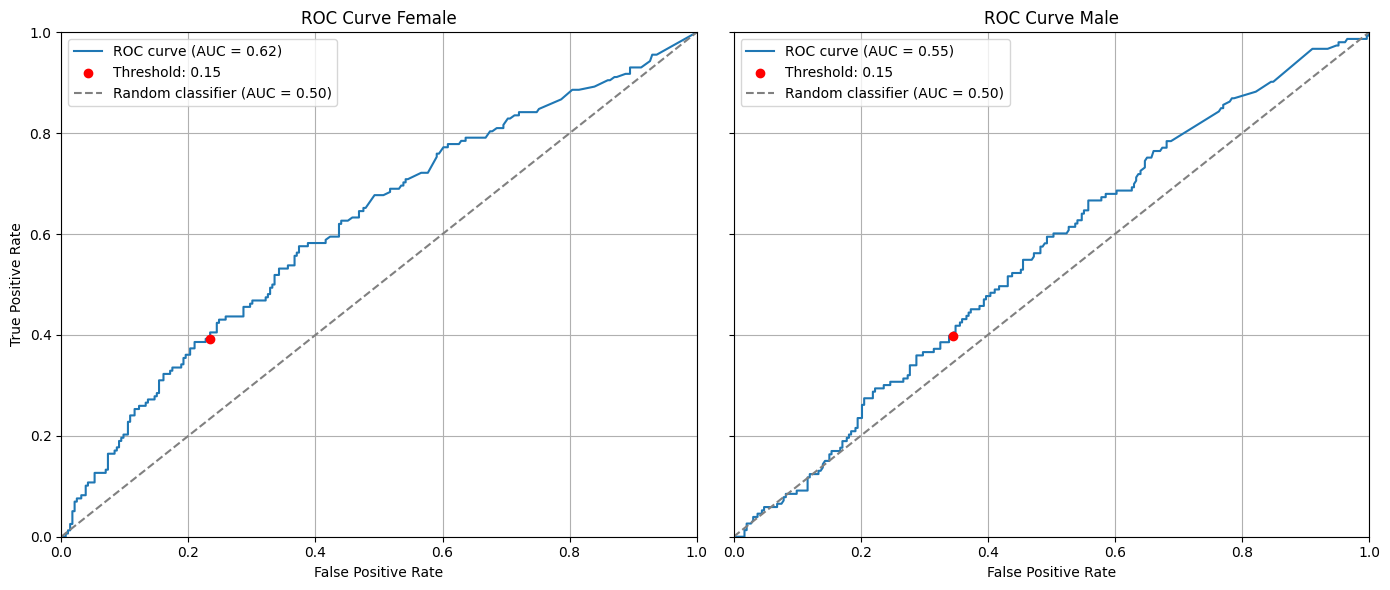

In [20]:
from sklearn.metrics import roc_auc_score

fpr_f, tpr_f, thres_f = roc_curve(df_female["Label"], df_female["predicted_risk"])
auc_f = roc_auc_score(df_female["Label"], df_female["predicted_risk"])

fpr_m, tpr_m, thres_m = roc_curve(df_male["Label"], df_male["predicted_risk"])
auc_m = roc_auc_score(df_male["Label"], df_male["predicted_risk"])

threshold = 0.15

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Female
axes[0].plot(fpr_f, tpr_f, label=f"ROC curve (AUC = {auc_f:.2f})")
idx_f = np.argmin(np.abs(thres_f - threshold))
axes[0].scatter(
    fpr_f[idx_f],
    tpr_f[idx_f],
    color="red",
    label=f"Threshold: {threshold:.2f}",
    zorder=5,
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier (AUC = 0.50)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve Female")
axes[0].legend()
axes[0].grid()

# Male
axes[1].plot(fpr_m, tpr_m, label=f"ROC curve (AUC = {auc_m:.2f})")
idx_m = np.argmin(np.abs(thres_m - threshold))
axes[1].scatter(
    fpr_m[idx_m],
    tpr_m[idx_m],
    color="red",
    label=f"Threshold: {threshold:.2f}",
    zorder=5,
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier (AUC = 0.50)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_title("ROC Curve Male")
axes[1].legend()
axes[1].grid()

plt.xlim([0, 1])
plt.ylim([0, 1])
plt.tight_layout()
plt.show()

# Failure analysis

In [21]:
pd.set_option("display.max_columns", None)

fn_mask_f = (df_female["Label"] == 1) & (df_female["pred_label"] == 0)
fn_female = df_female[fn_mask_f]

fn_mask_m = (df_male["Label"] == 1) & (df_male["pred_label"] == 0)
fn_male = df_male[fn_mask_m]

In [22]:
print(f"False negatives (female): {fn_mask_f.sum()} total female positives missed")
print(f"False negatives (male): {fn_mask_m.sum()} total male positives missed")

# FN rate relative to all actual positives, per group
fn_rate_female = len(fn_female) / (df_female["Label"] == 1).sum()
fn_rate_male = len(fn_male) / (df_male["Label"] == 1).sum()
print(f"FN rate - female: {fn_rate_female:.3f}, male: {fn_rate_male:.3f}")

False negatives (female): 96 total female positives missed
False negatives (male): 92 total male positives missed
FN rate - female: 0.608, male: 0.601


In [23]:
import numpy as np
from scipy import stats


def add_fn_flag(df):
    df = df.copy()
    df["is_fn"] = ((df["Label"] == 1) & (df["pred_label"] == 0)).astype(int)
    df["is_fp"] = ((df["Label"] == 0) & (df["pred_label"] == 1)).astype(int)
    return df


df_female = add_fn_flag(df_female)
df_male = add_fn_flag(df_male)

In [24]:
from statsmodels.stats.multitest import multipletests

# Age is always present
cols = [
    "Age",
    "BMI",
    "DiastolicBP",
    "SystolicBP",
    "ALAT",
    "ASAT",
    "CRP",
    "Cholesterol",
    "GGT",
    "Glucose",
    "HDL Cholesterol",
    "Hemoglobine",
    "Kalium",
    "Kreatinine",
    "LD",
    "LDL Cholesterol",
    "Leucocyten",
    "MCH",
    "MCHC",
    "MCV",
    "Natrium",
    "TSH",
    "Triglyceriden",
    "Trombocyten",
    "eGFR (CKD-EPI)",
    "ST_deviation_index_Anterior",  # all ECG features have the same data availability
]


def missingness_vs_error(df, cols, group_name, error_type="fn", correction="holm"):
    """
    error_type='fn': compares FN vs TP, restricted to actual positives (Label==1)
    error_type='fp': compares FP vs TN, restricted to actual negatives (Label==0)
    """
    if error_type == "fn":
        subset = df[df["Label"] == 1]
        error_flag = "is_fn"
        error_label, correct_label = "fn", "tp"
    elif error_type == "fp":
        subset = df[df["Label"] == 0]
        error_flag = "is_fp"
        error_label, correct_label = "fp", "tn"
    else:
        raise ValueError("error_type must be 'fn' or 'fp'")

    results = []
    for col in cols:
        is_missing = subset[col].isna().astype(int)
        table = pd.crosstab(is_missing, subset[error_flag])

        if table.shape == (2, 2):
            chi2, p_chi2, dof, expected = stats.chi2_contingency(table)
            if (expected >= 5).all():
                p = p_chi2
                test_used = "chi2"
            else:
                _, p = stats.fisher_exact(table)
                test_used = "fishers"
        else:
            p = np.nan
            test_used = None

        err_missing_rate = subset.loc[subset[error_flag] == 1, col].isna().mean()
        correct_missing_rate = subset.loc[subset[error_flag] == 0, col].isna().mean()
        results.append(
            {
                "column": col,
                "label": eng_col_labels.get(col, col),  # English name for display
                f"{error_label}_missing_rate": round(err_missing_rate, 2),
                f"{correct_label}_missing_rate": round(correct_missing_rate, 2),
                "diff": round(err_missing_rate - correct_missing_rate, 3),
                "p_value": p,
                "test": test_used,
            }
        )
    out = pd.DataFrame(results)

    valid = out["p_value"].notna()
    out["p_adjusted"] = np.nan
    out["significant"] = False
    if valid.any():
        reject, p_adj, _, _ = multipletests(out.loc[valid, "p_value"], method=correction)
        out.loc[valid, "p_adjusted"] = np.round(p_adj,3)
        out.loc[valid, "significant"] = reject

    return out


# False negatives: FN vs TP
missing_summary_fn_f = missingness_vs_error(df_female, cols, "female", error_type="fn")
missing_summary_fn_m = missingness_vs_error(df_male, cols, "male", error_type="fn")

# False positives: FP vs TN
missing_summary_fp_f = missingness_vs_error(df_female, cols, "female", error_type="fp")
missing_summary_fp_m = missingness_vs_error(df_male, cols, "male", error_type="fp")

In [25]:
missing_summary_fn_f

,column,label,fn_missing_rate,tp_missing_rate,diff,p_value,test,p_adjusted,significant
0,Age,Age,0.00,0.00,0.000,NaN,None,NaN,False
1,BMI,BMI,1.00,0.05,0.952,1.097455e-32,chi2,0.0,True
2,DiastolicBP,Diastolic BP,1.00,0.69,0.306,3.159993e-08,chi2,0.0,True
3,SystolicBP,Systolic BP,1.00,0.69,0.306,3.159993e-08,chi2,0.0,True
4,ALAT,ALAT,0.81,0.84,-0.026,8.352762e-01,chi2,1.0,False
5,ASAT,ASAT,0.86,0.84,0.026,8.264207e-01,chi2,1.0,False
6,CRP,CRP,0.93,0.89,0.040,5.639636e-01,chi2,1.0,False
7,Cholesterol,Cholesterol,0.88,0.92,-0.044,5.381247e-01,chi2,1.0,False
8,GGT,GGT,0.86,0.87,-0.006,1.000000e+00,chi2,1.0,False
9,Glucose,Glucose,0.80,0.82,-0.020,9.099849e-01,chi2,1.0,False


In [26]:
missing_summary_fn_f.to_csv("output/missingness_positive_labels_f.csv")
missing_summary_fn_m.to_csv("output/missingness_positive_labels_m.csv")
missing_summary_fp_f.to_csv("output/missingness_negative_labels_f.csv")
missing_summary_fp_m.to_csv("output/missingness_negative_labels_m.csv")

# Figure 4 - side by side missingness rate

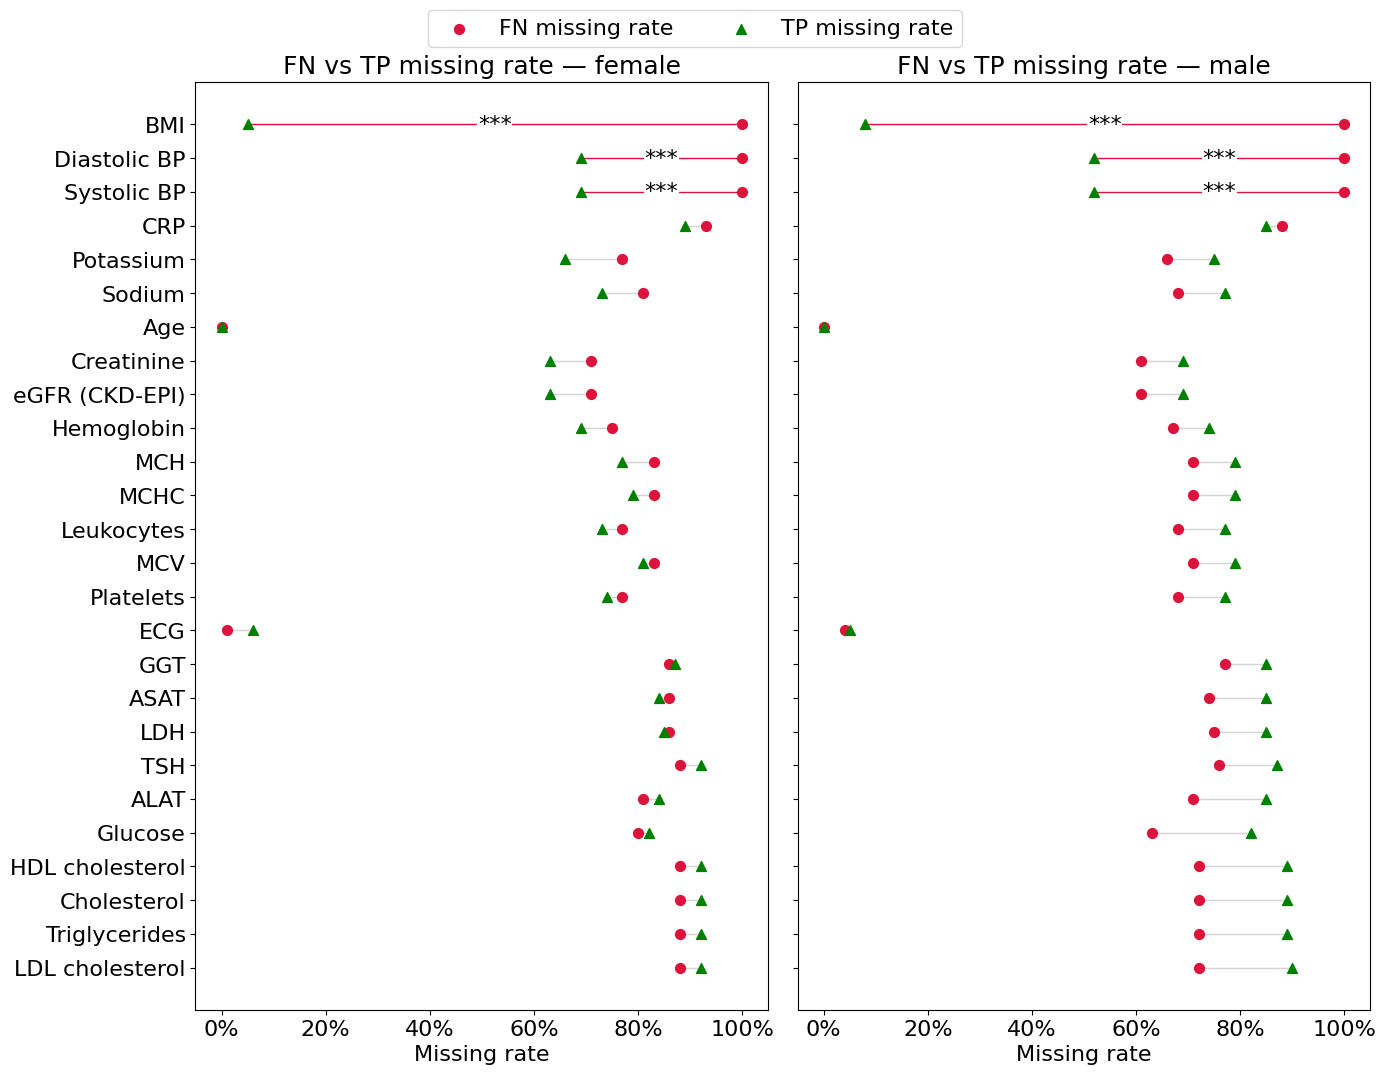

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter


def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


def get_shared_order(df_female, df_male, label_col=None, sort_by="mean_diff"):
    """Set a predictor order shared by both panels."""
    f = df_female.copy()
    m = df_male.copy()

    if label_col:
        f = f.set_index(label_col)
        m = m.set_index(label_col)

    # only keep predictors present in both datasets
    common = f.index.intersection(m.index)
    f, m = f.loc[common], m.loc[common]

    if sort_by == "mean_diff":
        order = ((f["diff"] + m["diff"]) / 2).sort_values().index
    elif sort_by == "female_diff":
        order = f["diff"].sort_values().index
    else:
        order = common.sort_values()  # alphabetical fallback

    return order


def plot_panel(ax, missing_summary, order, title="FN vs TP", gender="female", label_col=None):
    df = missing_summary.copy()
    if label_col:
        df = df.set_index(label_col)
    df = df.loc[order]  # apply shared order
    df["significant"] = df["p_adjusted"] < 0.05

    label_map = {**eng_col_labels, "ST_deviation_index_Anterior": "ECG"}  # all ECG features have the same missingness%
    labels = [label_map.get(lbl, lbl) for lbl in df.index.astype(str)]

    y = np.arange(len(df))

    for i, row in enumerate(df.itertuples()):
        color = "crimson" if row.significant else "lightgray"
        ax.plot([row.fn_missing_rate, row.tp_missing_rate], [i, i], color=color, linewidth=1, zorder=1)

        if row.significant:
            x_mid = (row.fn_missing_rate + row.tp_missing_rate) / 2
            stars = p_to_stars(row.p_adjusted)
            ax.text(
                x_mid,
                i,
                stars,
                fontsize=16,
                color="black",
                ha="center",
                va="center",
                zorder=3,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.5),
            )

    ax.scatter(df["fn_missing_rate"], y, color="crimson", marker="o", label="FN missing rate", zorder=2, s=50)
    ax.scatter(df["tp_missing_rate"], y, color="green", marker="^", label="TP missing rate", zorder=2, s=50)

    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

    ax.tick_params(axis="x", labelsize=16)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=16)
    ax.set_xlabel("Missing rate", fontsize=16)
    ax.set_title(f"{title} missing rate — {gender}", fontsize=18)


def plot_false_vs_true(df_female, df_male, title="FN vs TP", label_col=None, sort_by="mean_diff"):
    order = get_shared_order(df_female, df_male, label_col=label_col, sort_by=sort_by)
    n = len(order)

    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, n * 0.4)), sharex=True, sharey=True)

    plot_panel(axes[0], df_female, order, title=title, gender="female", label_col=label_col)
    plot_panel(axes[1], df_male, order, title=title, gender="male", label_col=label_col)

    handles, labels_ = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04), fontsize=16)

    plt.tight_layout()
    fig.savefig("output/Figure4.png", dpi=300, bbox_inches="tight")
    plt.show()


plot_false_vs_true(missing_summary_fn_f, missing_summary_fn_m, label_col="column")

## Value comparison

In [28]:
# Age is always present
cols_values = [
    "Age",
    "BMI",
    "DiastolicBP",
    "SystolicBP",
    "ALAT",
    "ASAT",
    "CRP",
    "Cholesterol",
    "GGT",
    "Glucose",
    "HDL Cholesterol",
    "Hemoglobine",
    "Kalium",
    "Kreatinine",
    "LD",
    "LDL Cholesterol",
    "Leucocyten",
    "MCH",
    "MCHC",
    "MCV",
    "Natrium",
    "TSH",
    "Triglyceriden",
    "Trombocyten",
    "eGFR (CKD-EPI)",
    "InjClsInfarction",
    "ST_deviation_index_Anterior",
    "ST_deviation_index_Inferior",
    "ST_deviation_index_Lateral",
    "T_morphology_score_Anterior",
    "T_morphology_score_Inferior",
    "T_morphology_score_Lateral",
    "Regional_ischemia_Anterior",
    "Regional_ischemia_Inferior",
    "Regional_ischemia_Lateral",
]

In [29]:
import numpy as np
import pandas as pd
from scipy import stats  # noqa: F811


def compare_predictor_values(df, cols, error_type="fn", min_n=2, correction="holm"):
    """
    Compare observed predictor values between error and correct predictions
    using the Mann-Whitney U test.

    error_type='fn': FN vs TP, restricted to actual positives (Label==1)
    error_type='fp': FP vs TN, restricted to actual negatives (Label==0)
    """
    if error_type == "fn":
        subset = df[df["Label"] == 1]
        error_flag, error_label, correct_label = "is_fn", "FN", "TP"
    elif error_type == "fp":
        subset = df[df["Label"] == 0]
        error_flag, error_label, correct_label = "is_fp", "FP", "TN"
    else:
        raise ValueError("error_type must be 'fn' or 'fp'")

    results = []
    for col in cols:
        correct = subset.loc[subset[error_flag] == 0, col].dropna()
        error = subset.loc[subset[error_flag] == 1, col].dropna()

        if len(correct) >= min_n and len(error) >= min_n:
            u, p = stats.mannwhitneyu(error, correct, alternative="two-sided")
            r = 1 - 2 * u / (len(error) * len(correct))  # rank-biserial effect size
        else:
            p, r = np.nan, np.nan

        if len(correct):
            q1, q3 = correct.quantile([0.25, 0.75])
            correct_summary = f"{correct.median():.2f} (IQR {q1:.2f} – {q3:.2f})"
        else:
            correct_summary = np.nan

        if len(error):
            q1, q3 = error.quantile([0.25, 0.75])
            error_summary = f"{error.median():.2f} (IQR {q1:.2f} – {q3:.2f})"
        else:
            error_summary = np.nan

        results.append(
            {
                "column": col,
                "label": eng_col_labels_with_units.get(col, col),
                f"{correct_label}_median": correct_summary,
                f"{error_label}_median": error_summary,
                f"{correct_label}_n": len(correct),
                f"{error_label}_n": len(error),
                "effect_size_r": round(r, 2) if not np.isnan(r) else np.nan,
                "p_value": p,
            }
        )

    out = pd.DataFrame(results)

    # multiple test correction across predictors
    out["p_adjusted"] = np.nan
    out["significant"] = False
    valid = out["p_value"].notna()
    if valid.any():
        reject, p_adj, _, _ = multipletests(out.loc[valid, "p_value"], method=correction)
        out.loc[valid, "p_adjusted"] = np.round(p_adj, 3)
        out.loc[valid, "significant"] = reject

    return out


value_summary_fn_f = compare_predictor_values(df_female, cols_values, error_type="fn")
value_summary_fn_m = compare_predictor_values(df_male, cols_values, error_type="fn")
value_summary_fp_f = compare_predictor_values(df_female, cols_values, error_type="fp")
value_summary_fp_m = compare_predictor_values(df_male, cols_values, error_type="fp")

In [30]:
value_summary_fn_f.to_csv("output/distribution_positive_labels_f.csv")
value_summary_fn_m.to_csv("output/distribution_positive_labels_m.csv")
value_summary_fp_f.to_csv("output/distribution_negative_labels_f.csv")
value_summary_fp_m.to_csv("output/distribution_negative_labels_m.csv")

# Compare data availability silent trial with development set:

In [31]:
import os

file_path = "../data/train_test"

train_f = pd.read_parquet(os.path.join(file_path, "train_val_data_f.parquet"))
test_f = pd.read_parquet(os.path.join(file_path, "test_data_f.parquet"))

train_m = pd.read_parquet(os.path.join(file_path, "train_val_data_m.parquet"))
test_m = pd.read_parquet(os.path.join(file_path, "test_data_m.parquet"))


In [32]:
def split_X_y(df, target_col="y"):
    X = df.drop(columns=[target_col])
    y = df[target_col]
    return X, y


train_f, y_train_f = split_X_y(train_f, target_col="y")
test_f, y_test_f = split_X_y(test_f, target_col="y")

train_m, y_train_m = split_X_y(train_m, target_col="y")
test_m, y_test_m = split_X_y(test_m, target_col="y")

In [33]:
cols_missing_check = train_f.columns

In [34]:
def drop_high_missing_rows(df, cols, threshold=0.8):
    df = df[cols].copy()
    df["missing_fraction"] = df.isnull().mean(axis=1)
    df = df.loc[df["missing_fraction"] < threshold]
    return df

In [35]:
train_f = drop_high_missing_rows(train_f, cols_missing_check)
test_f = drop_high_missing_rows(test_f, cols_missing_check)

train_m = drop_high_missing_rows(train_m, cols_missing_check)
test_m = drop_high_missing_rows(test_m, cols_missing_check)


### first look at the outcome distribution

In [36]:
import pandas as pd


def label_distribution(labels_dict):
    rows = []
    for name, labels in labels_dict.items():
        labels = pd.Series(labels)
        counts = labels.value_counts()
        props = labels.value_counts(normalize=True)
        for label in counts.index:
            rows.append({"split": name, "label": label, "count": counts[label], "proportion": props[label]})
    return pd.DataFrame(rows)


female_dist = label_distribution({"silent": df_female["Label"], "train": y_train_f, "test": y_test_f})

male_dist = label_distribution({"silent": df_male["Label"], "train": y_train_m, "test": y_test_m})

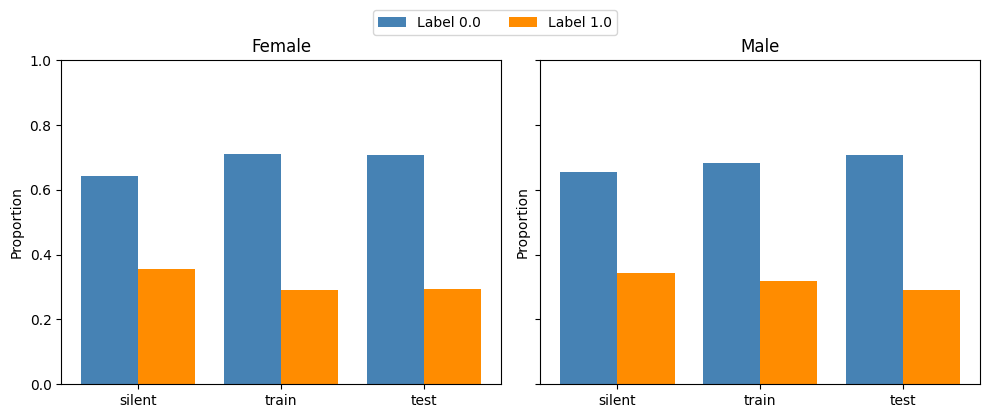

In [37]:
import matplotlib.pyplot as plt
import numpy as np


def plot_label_distribution(ax, dist_df, title):
    splits = dist_df["split"].unique()
    labels = sorted(dist_df["label"].unique())
    x = np.arange(len(splits))
    bar_width = 0.8 / len(labels)
    colors = ["steelblue", "darkorange"]

    for i, label in enumerate(labels):
        vals = [
            dist_df[(dist_df["split"] == s) & (dist_df["label"] == label)]["proportion"].values[0]
            if len(dist_df[(dist_df["split"] == s) & (dist_df["label"] == label)])
            else 0
            for s in splits
        ]
        ax.bar(x + i * bar_width, vals, width=bar_width, label=f"Label {label}", color=colors[i % len(colors)])

    ax.set_xticks(x + bar_width * (len(labels) - 1) / 2)
    ax.set_xticklabels(splits)
    ax.set_ylabel("Proportion")
    ax.set_title(title)
    ax.set_ylim(0, 1)


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
plot_label_distribution(axes[0], female_dist, "Female")
plot_label_distribution(axes[1], male_dist, "Male")

handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05))

plt.tight_layout()
plt.show()

In [38]:
# combine test and train from the retraining set:
train_test_f = pd.concat([train_f, test_f], ignore_index=True)
train_test_m = pd.concat([train_m, test_m], ignore_index=True)

In [39]:
from itertools import combinations

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests


def missingness_table(dfs_dict, col):
    """Build a group (present/missing) contingency table for one predictor."""
    rows = {}
    for name, df in dfs_dict.items():
        n_missing = df[col].isna().sum()
        n_present = df[col].notna().sum()
        rows[name] = {"present": n_present, "missing": n_missing}
    return pd.DataFrame(rows).T  # rows = datasets, cols = present/missing

In [40]:
def two_group_missingness_test(dfs_dict, col):
    table = missingness_table(dfs_dict, col)

    # skip if a group is empty or nothing/everything is missing
    if (table.sum(axis=1) == 0).any() or (table.sum(axis=0) == 0).any():
        return np.nan, "skipped", table

    _, p_chi2, _, expected = stats.chi2_contingency(table)
    if (expected >= 5).all():
        return p_chi2, "chi2", table
    _, p_fisher = stats.fisher_exact(table)
    return p_fisher, "fisher", table

In [41]:
def missingness_significance_report(dfs_dict, cols, alpha=0.05, correction="holm"):
    assert len(dfs_dict) == 2, "Expected exactly two groups"
    g1, g2 = dfs_dict.keys()

    rows = []
    for col in cols:
        p, test_used, table = two_group_missingness_test(dfs_dict, col)
        rows.append(
            {
                "predictor": col,
                "test": test_used,
                f"pct_missing_{g1}": round(100 * table.loc[g1, "missing"] / table.loc[g1].sum(), 2),
                f"pct_missing_{g2}": round(100 * table.loc[g2, "missing"] / table.loc[g2].sum(), 2),
                "p_raw": round(p, 3),
            }
        )

    report = pd.DataFrame(rows)

    # correct across predictors
    report["p_adjusted"] = np.nan
    report["significant"] = False
    valid = report["p_raw"].notna()
    if valid.any():
        reject, p_adj, _, _ = multipletests(report.loc[valid, "p_raw"], alpha=alpha, method=correction)
        report.loc[valid, "p_adjusted"] = np.round(p_adj, 3)
        report.loc[valid, "significant"] = reject

    return report


In [42]:
dfs_female = {"development": train_test_f, "silent": df_female}
report_f = missingness_significance_report(dfs_female, cols)

In [43]:
report_f.to_csv("output/missing_distribution_stats_f.csv")

In [44]:
dfs_male = {"development": train_test_m, "silent": df_male}

report_m = missingness_significance_report(dfs_male, cols)

In [45]:
report_m.to_csv("output/missing_distribution_stats_m.csv")

# Figure 5 Missingness rate silent trial vs train vs test set

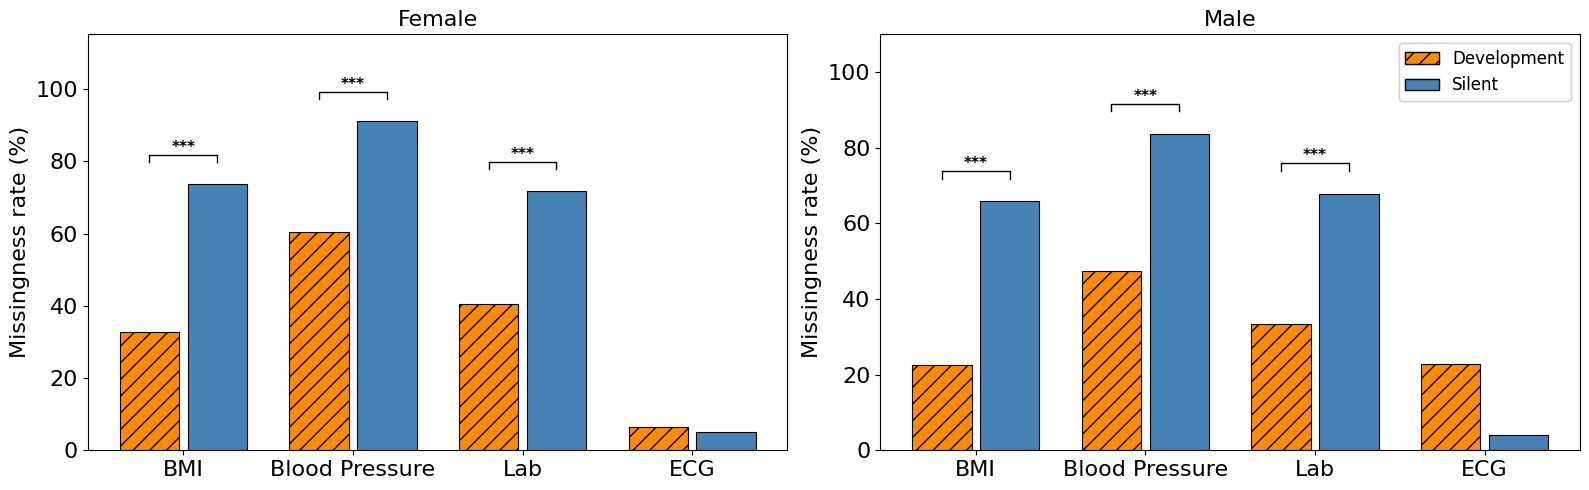

In [46]:
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# def p_to_stars(p):
#     if p < 0.001:
#         return "***"
#     elif p < 0.01:
#         return "**"
#     elif p < 0.05:
#         return "*"
#     else:
#         return ""


def draw_bracket(ax, x1, x2, y, height, text):
    """Draw a horizontal bracket between x1 and x2 at height y, with a label above it."""
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y], color="black", linewidth=1)
    ax.text((x1 + x2) / 2, y + height, text, ha="center", va="bottom", fontsize=11, fontweight="bold")


def plot_missingness_panel(
    ax,
    dfs_dict,
    cols,
    report_df=None,
    x_labels=None,
    colors=None,
    hatches=None,
    gender=None,
    bar_gap=0.05,
    bracket_gap=6,
    bracket_step=8,
):
    n_cols = len(cols)
    n_datasets = len(dfs_dict)
    dataset_names = list(dfs_dict.keys())
    x_labels = x_labels or cols

    if colors is None:
        colors = plt.cm.tab10.colors[:n_datasets]

    if hatches is None:
        hatches = [""] * n_datasets

    group_width = 0.8
    slot_width = group_width / n_datasets
    bar_width = slot_width - bar_gap

    dataset_x_offset = {name: (j - (n_datasets - 1) / 2) * slot_width for j, name in enumerate(dataset_names)}

    max_top = 0

    for i, col in enumerate(cols):
        bar_tops = {}
        for j, name in enumerate(dataset_names):
            pct_miss = dfs_dict[name][col].isna().mean() * 100
            ax.bar(
                i + dataset_x_offset[name],
                pct_miss,
                width=bar_width,
                color=colors[j],
                hatch=hatches[j],
                edgecolor="black",
                linewidth=0.8,
            )
            bar_tops[name] = pct_miss

        if report_df is not None:
            row = report_df[report_df["predictor"] == col]
            if not row.empty and bool(row["significant"].iloc[0]):
                stars = p_to_stars(row["p_adjusted"].iloc[0])
                if stars:
                    g1, g2 = dataset_names
                    x1 = i + dataset_x_offset[g1]
                    x2 = i + dataset_x_offset[g2]
                    y = max(bar_tops.values()) + bracket_gap
                    draw_bracket(ax, x1, x2, y, height=2, text=stars)
                    max_top = max(max_top, y + bracket_step)

    ax.tick_params(axis="x", labelsize=16)
    ax.tick_params(axis="y", labelsize=16)
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(x_labels, fontsize=16)
    ax.set_ylabel("Missingness rate (%)", fontsize=16)
    ax.set_ylim(0, max(110, max_top + 10))
    ax.set_title(f"{gender}", fontsize=16)

    return colors, dataset_names


def plot_missingness_comparison(
    dfs_dict_female, dfs_dict_male, cols, report_f=None, report_m=None, x_labels=None, colors=None, hatches=None
):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True)

    colors, dataset_names = plot_missingness_panel(
        axes[0],
        dfs_dict_female,
        cols,
        report_df=report_f,
        x_labels=x_labels,
        colors=colors,
        hatches=hatches,
        gender="Female",
    )
    plot_missingness_panel(
        axes[1],
        dfs_dict_male,
        cols,
        report_df=report_m,
        x_labels=x_labels,
        colors=colors,
        hatches=hatches,
        gender="Male",
    )

    # group legend (colors + hatches)
    legend_label_map = {"train_val": "Train", "test": "Test", "silent": "Silent"}
    hatches = hatches or [""] * len(dataset_names)
    group_handles = [
        mpatches.Patch(facecolor=colors[j], hatch=hatches[j], edgecolor="black", label=legend_label_map.get(name, name))
        for j, name in enumerate(dataset_names)
    ]
    group_legend = fig.legend(handles=group_handles, fontsize=12, loc="upper right", bbox_to_anchor=(0.99, 0.92))
    fig.add_artist(group_legend)

    plt.tight_layout()
    fig.savefig("output/Figure5.png", dpi=300, bbox_inches="tight")
    plt.show()


hatches = ["//", ""]

plot_missingness_comparison(
    {"Development": train_test_f, "Silent": df_female},
    {"Development": train_test_m, "Silent": df_male},
    cols=["BMI", "SystolicBP", "Hemoglobine", "ST_deviation_index_Inferior"],
    report_f=report_f,
    report_m=report_m,
    x_labels=["BMI", "Blood Pressure", "Lab", "ECG"],
    hatches=hatches,
    colors=["darkorange", "steelblue"],
)

### Test feature importance

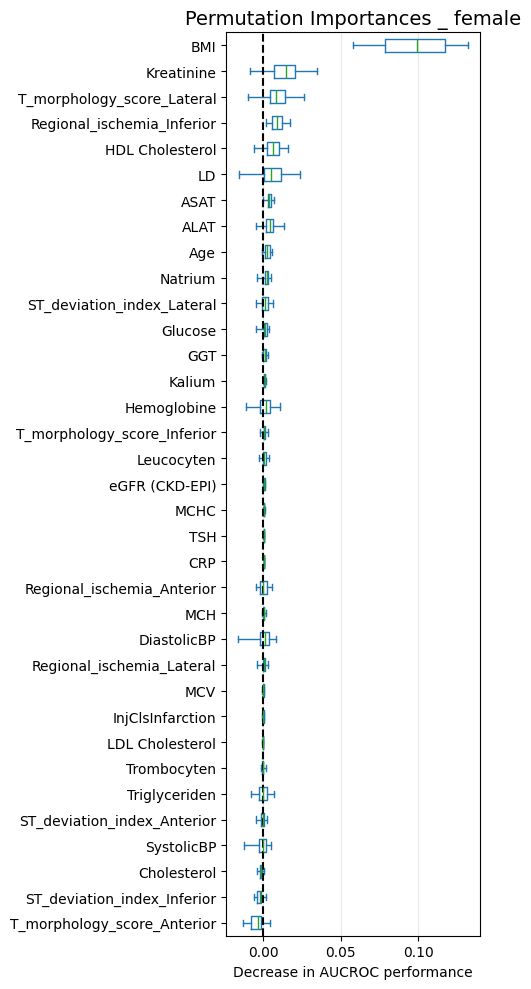

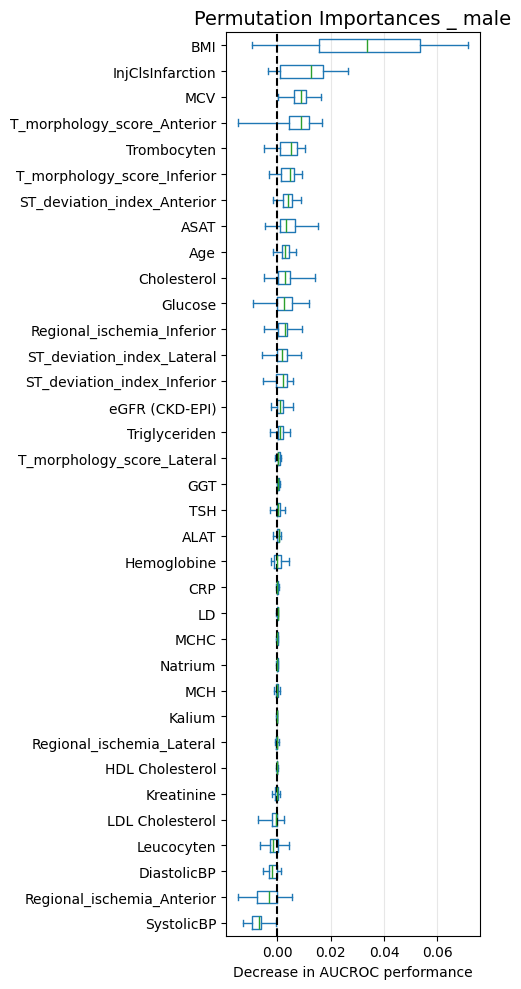

In [47]:
from sklearn.inspection import permutation_importance

data = {"female": (df_female, model_f), "male": (df_male, model_m)}

importance_results = {}

for gender, (df_ext, model) in data.items():
    X_ext = df_ext[input_cols]
    y_ext = df_ext["Label"]

    result = permutation_importance(model, X_ext, y_ext, scoring="roc_auc", n_repeats=30, random_state=42)

    importance_results[gender] = result

    sorted_importances_idx = result.importances_mean.argsort()
    importances = pd.DataFrame(
        result.importances[sorted_importances_idx].T,
        columns=X_ext.columns[sorted_importances_idx],
    )

    n_features = importances.shape[1]

    fig, ax = plt.subplots(figsize=(5, 10))  # fig_height))
    importances.plot.box(vert=False, whis=10, ax=ax)

    ax.set_title(f"Permutation Importances _ {gender}", fontsize=14)
    ax.axvline(x=0, color="k", linestyle="--")
    ax.set_xlabel("Decrease in AUCROC performance")
    ax.grid(True, axis="x", alpha=0.3)

    fig.tight_layout()
    plt.show()